In [1]:
import json
import matplotlib.pyplot as plt
import pandas as pd
import os

In [4]:

# 1. 检查并读取数据文件
file_path = "./performance_data.json"  # 假设文件已移动到当前目录

with open(file_path, 'r') as f:
    data = json.load(f)
df = pd.DataFrame(data)
df['frame'] = df.index + 1  # 添加帧序号列 (从1开始)
df


,delta,status,frame
0,0.0,False,1
1,153.9,False,2
2,9.6,False,3
3,10.2,False,4
4,17.1,False,5
5,16.1,False,6
6,16.7,False,7
7,17.4,False,8
8,16.0,False,9
9,17.2,False,10


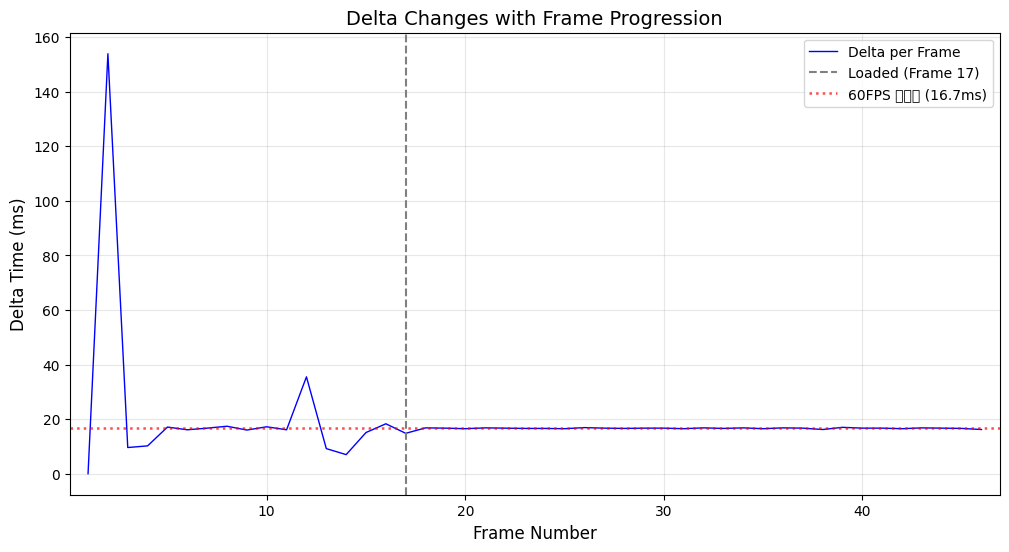

In [7]:
critical_frame = None
for i in range(1, len(df)):
    if df.loc[i-1, 'status'] == False and df.loc[i, 'status'] == True:
        critical_frame = df.loc[i, 'frame']
        break

plt.figure(figsize=(12, 6))

plt.plot(df['frame'], df['delta'], 
         label='Delta per Frame', 
         color='blue', 
         linewidth=1)


if critical_frame is not None:
    plt.axvline(x=critical_frame, 
                color='gray', 
                linestyle='--', 
                linewidth=1.5,
                label=f'Loaded (Frame {critical_frame})')
plt.axhline(y=16.7, 
          color='red', 
          linestyle=':', 
          linewidth=1.8,
          alpha=0.7,
          label='60FPS 参考线 (16.7ms)')

plt.title('Delta Changes with Frame Progression', fontsize=14)
plt.xlabel('Frame Number', fontsize=12)
plt.ylabel('Delta Time (ms)', fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend()

margin = len(df) * 0.02  # 2%的边距
plt.xlim(df['frame'].min()-margin, df['frame'].max()+margin)

# output_file = "./images/changetodelay.png"
# plt.savefig(output_file, dpi=300, bbox_inches='tight')

plt.show()